# This notebook demonstrates a series of experiments conducted with SPAg on the AI4I-2021 dataset

## Step 0. Setup the experiment

In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
import os
import pandas as pd
import numpy as np
from support.preproc import load_reg_windows
from spag.models import DeepForecaster, BaseForecaster
from support.evaluate import ForecastEstimator

In [5]:
data_dir = os.path.join('data', 'spag')
model_directory = os.path.join('models', 'spag')

In [6]:
test = {}
valid = {}
models = {}

In [7]:
look_back_length = 60
horizon = 15

## Step 1. Load data

In [8]:
for state in os.listdir(data_dir):
    test[state] = load_reg_windows(os.path.join(data_dir, state, 'test'))
    print('test', state,  'data shape:', test[state].data.shape, 'targets shape:', test[state].targets.shape)
    valid[state] = load_reg_windows(os.path.join(data_dir, state, 'valid'))
    print('valid', state,  'data shape:', valid[state].data.shape, 'targets shape:', valid[state].targets.shape)

test c25-75 data shape: (1646, 60, 3) targets shape: (1646, 15, 3)
valid c25-75 data shape: (785, 60, 3) targets shape: (785, 15, 3)
test cap data shape: (781, 60, 3) targets shape: (781, 15, 3)
valid cap data shape: (354, 60, 3) targets shape: (354, 15, 3)
test off data shape: (886, 60, 3) targets shape: (886, 15, 3)
valid off data shape: (406, 60, 3) targets shape: (406, 15, 3)
test on data shape: (784, 60, 3) targets shape: (784, 15, 3)
valid on data shape: (355, 60, 3) targets shape: (355, 15, 3)
test out data shape: (816, 60, 3) targets shape: (816, 15, 3)
valid out data shape: (370, 60, 3) targets shape: (370, 15, 3)
test unb data shape: (784, 60, 3) targets shape: (784, 15, 3)
valid unb data shape: (354, 60, 3) targets shape: (354, 15, 3)
test vnt data shape: (778, 60, 3) targets shape: (778, 15, 3)
valid vnt data shape: (351, 60, 3) targets shape: (351, 15, 3)


## Step 2. Load models

In [9]:
for state in os.listdir(model_directory):
    models[state.split('_')[1]] = {}
    state_dir = os.path.join(model_directory, state)
    for model_name in os.listdir(state_dir):
        model = DeepForecaster(from_file=os.path.join(state_dir, model_name))
        model.default_name = f"{state}_{model_name.replace('.keras', '')}"
        model.model._name = model.default_name
        print(model.summary())
        models[state.split('_')[1]][model_name.replace('.keras', '')] = model



Model: "01_off_GRU-1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 gru_3 (GRU)                 (None, 32)                3552      
                                                                 
 dropout_9 (Dropout)         (None, 32)                0         
                                                                 
 dense_7 (Dense)             (None, 45)                1485      
                                                                 
 reshape_7 (Reshape)         (None, 15, 3)             0         
                                                                 
Total params: 5037 (19.68 KB)
Trainable params: 5037 (19.68 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
None
Model: "01_off_GRU-3"
_________________________________________________________________
 Layer (type)                Output Shape              Pa

## Step 3. Validation

### Forecasting

In [10]:
valid_predictions = {}
for state, windows in valid.items():
    valid_predictions[state] = {}
    for model_name, model in models[state].items():
        print(state, model_name)
        valid_predictions[state][model_name] = model.forecasting(windows.data, verbose=1)

c25-75 GRU-1
79/79 [==============================] - 0s 3ms/step
c25-75 GRU-3
79/79 [==============================] - 1s 5ms/step
c25-75 LSTM-1
79/79 [==============================] - 0s 2ms/step
cap GRU-1
36/36 [==============================] - 0s 3ms/step
cap GRU-3
36/36 [==============================] - 1s 5ms/step
cap LSTM-1
36/36 [==============================] - 0s 2ms/step
off GRU-1
41/41 [==============================] - 0s 3ms/step
off GRU-3
41/41 [==============================] - 1s 5ms/step
off LSTM-1
41/41 [==============================] - 0s 2ms/step
on GRU-1
36/36 [==============================] - 0s 3ms/step
on GRU-3
36/36 [==============================] - 1s 5ms/step
on LSTM-1
36/36 [==============================] - 0s 2ms/step
out GRU-1
37/37 [==============================] - 0s 3ms/step
out GRU-3
37/37 [==============================] - 1s 5ms/step
out LSTM-1
37/37 [==============================] - 0s 2ms/step
unb GRU-1
36/36 [===========================

### Evaluation on validation data

In [11]:
estimators = {}
for state, data in valid.items():
    estimator = ForecastEstimator()
    estimator.set_true_values(data.targets)
    for model_name, preds in valid_predictions[state].items():
        estimator.set_pred_values(preds, model_name=model_name)
    estimator.estimate()
    estimators[state] = estimator

Connected with Table 4, regression models GRU-1, GRU-3, LSTM-1

In [12]:
model_names = ['GRU-1', 'GRU-3', 'LSTM-1']
for model_name in model_names:
    loss = round(np.mean([estimator.quality.loc['ALL_FEATURES', f'{model_name}_MSE'] for state, estimator in estimators.items()]), 5)
    print(model_name, loss)

GRU-1 0.02609
GRU-3 0.02777
LSTM-1 0.02628


## Step 4. Testing

### SPAg models

In [28]:
test_predictions = {}
for state, windows in test.items():
    test_predictions[state] = {}
    for model_name, model in models[state].items():
        print(state, model_name)
        test_predictions[state][model_name] = model.forecasting(windows.data, verbose=1)

c25-75 GRU-1
165/165 [==============================] - 1s 3ms/step
c25-75 GRU-3
165/165 [==============================] - 1s 5ms/step
c25-75 LSTM-1
165/165 [==============================] - 0s 2ms/step
cap GRU-1
79/79 [==============================] - 0s 3ms/step
cap GRU-3
79/79 [==============================] - 0s 5ms/step
cap LSTM-1
79/79 [==============================] - 0s 3ms/step
off GRU-1
89/89 [==============================] - 0s 3ms/step
off GRU-3
89/89 [==============================] - 0s 5ms/step
off LSTM-1
89/89 [==============================] - 0s 2ms/step
on GRU-1
79/79 [==============================] - 0s 3ms/step
on GRU-3
79/79 [==============================] - 0s 5ms/step
on LSTM-1
79/79 [==============================] - 0s 2ms/step
out GRU-1
82/82 [==============================] - 0s 3ms/step
out GRU-3
82/82 [==============================] - 1s 5ms/step
out LSTM-1
82/82 [==============================] - 0s 2ms/step
unb GRU-1
79/79 [=====================

### Naive forecasting

In [29]:
nm = BaseForecaster(model_params={'look_back_length': look_back_length, 'horizon': horizon}, how='naive')
for state, windows in test.items():
    print(state)
    test_predictions[state]['naive'] = nm.forecasting(windows.data, forecasting_data_length=horizon, verbose=1)

c25-75
Forecasting: 100%|██████████| 1646/1646 [00:00<00:00, 54739.69it/s]
cap
Forecasting: 100%|██████████| 781/781 [00:00<00:00, 64893.35it/s]
off
Forecasting: 100%|██████████| 886/886 [00:00<00:00, 65549.87it/s]
on
Forecasting: 100%|██████████| 784/784 [00:00<00:00, 92229.04it/s]
out
Forecasting: 100%|██████████| 816/816 [00:00<00:00, 82332.26it/s]
unb
Forecasting: 100%|██████████| 784/784 [00:00<00:00, 79833.32it/s]
vnt
Forecasting: 100%|██████████| 778/778 [00:00<00:00, 78717.82it/s]


### Mean forecasting

In [30]:
nm = BaseForecaster(model_params={'look_back_length': look_back_length, 'horizon': horizon}, how='mean')
for state, windows in test.items():
    print(state)
    test_predictions[state]['mean'] = nm.forecasting(windows.data, forecasting_data_length=horizon, verbose=1)

c25-75
Forecasting: 100%|██████████| 1646/1646 [00:00<00:00, 12004.50it/s]
cap
Forecasting: 100%|██████████| 781/781 [00:00<00:00, 12616.42it/s]
off
Forecasting: 100%|██████████| 886/886 [00:00<00:00, 12148.50it/s]
on
Forecasting: 100%|██████████| 784/784 [00:00<00:00, 11824.16it/s]
out
Forecasting: 100%|██████████| 816/816 [00:00<00:00, 12785.60it/s]
unb
Forecasting: 100%|██████████| 784/784 [00:00<00:00, 13266.58it/s]
vnt
Forecasting: 100%|██████████| 778/778 [00:00<00:00, 13632.95it/s]


### Evaluation on test data

Connected with Table 7, regression models GRU-1, GRU-3, LSTM-1 as well as Naive and Mean approaches

In [31]:
estimators = {}
for state, data in test.items():
    estimator = ForecastEstimator()
    estimator.set_true_values(data.targets)
    for model_name, preds in test_predictions[state].items():
        estimator.set_pred_values(preds, model_name=model_name)
    estimator.estimate()
    estimators[state] = estimator

In [32]:
result = pd.DataFrame(columns=['state', 'model_name', 'MSE', 'MAE'])
i = 0
for state, estimator in estimators.items():
    model_names = list(estimator.pred.keys())
    for model_name in model_names:
        result.loc[i, 'state'] = state
        result.loc[i, 'model_name'] = model_name
        result.loc[i, 'MSE'] = estimator.quality.loc['ALL_FEATURES', f'{model_name}_MSE']
        result.loc[i, 'MAE'] = estimator.quality.loc['ALL_FEATURES', f'{model_name}_MAE']
        i = i + 1
result

,state,model_name,MSE,MAE
0,c25-75,GRU-1,0.029822,0.12994
1,c25-75,GRU-3,0.03115,0.13398
2,c25-75,LSTM-1,0.029677,0.12954
3,c25-75,naive,0.231531,0.3713
4,c25-75,mean,0.108527,0.25838
5,cap,GRU-1,0.04307,0.15866
6,cap,GRU-3,0.046417,0.16634
7,cap,LSTM-1,0.045959,0.16476
8,cap,naive,0.23986,0.3721
9,cap,mean,0.113278,0.26067


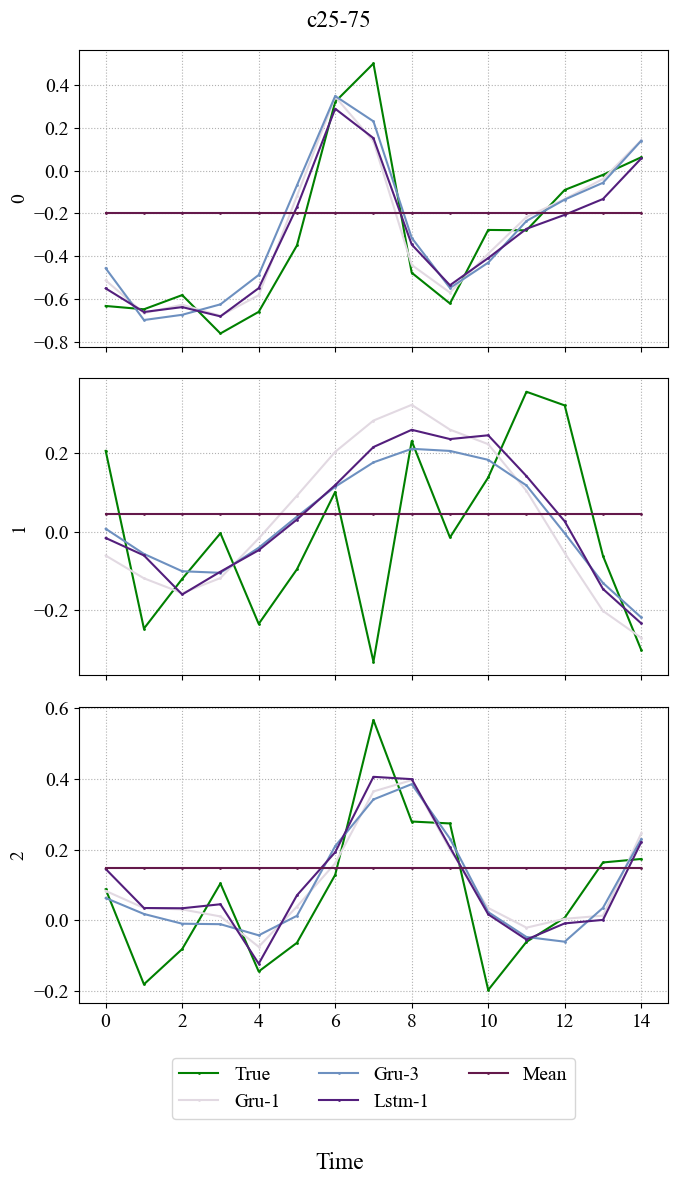

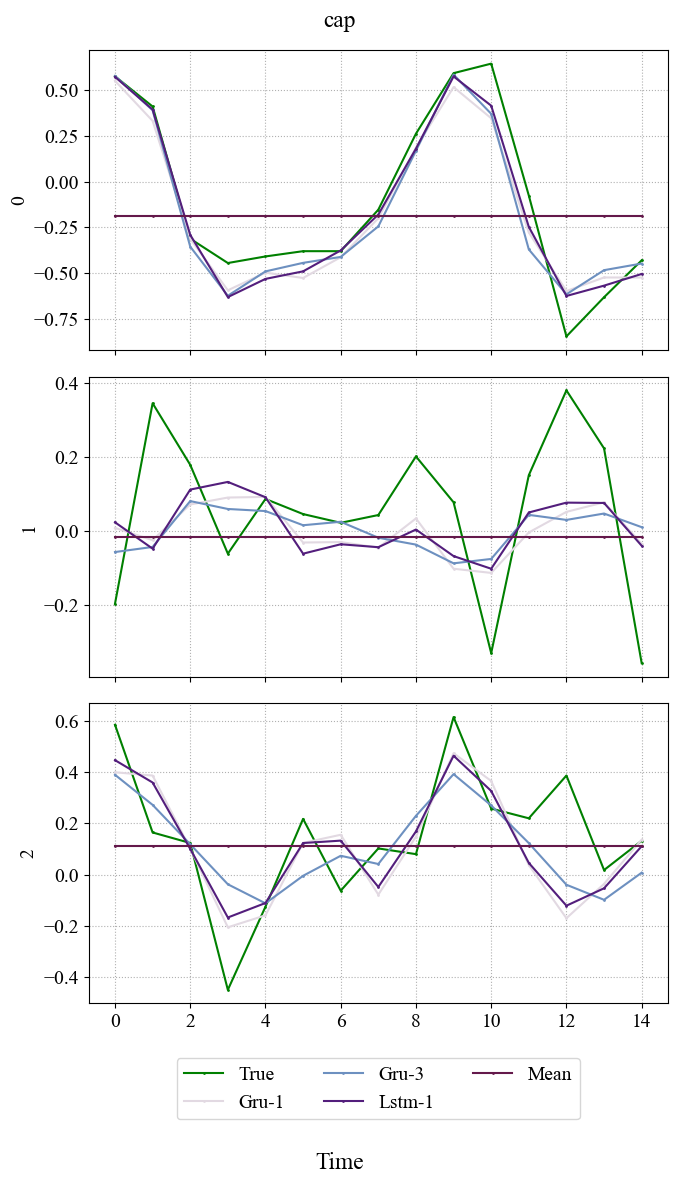

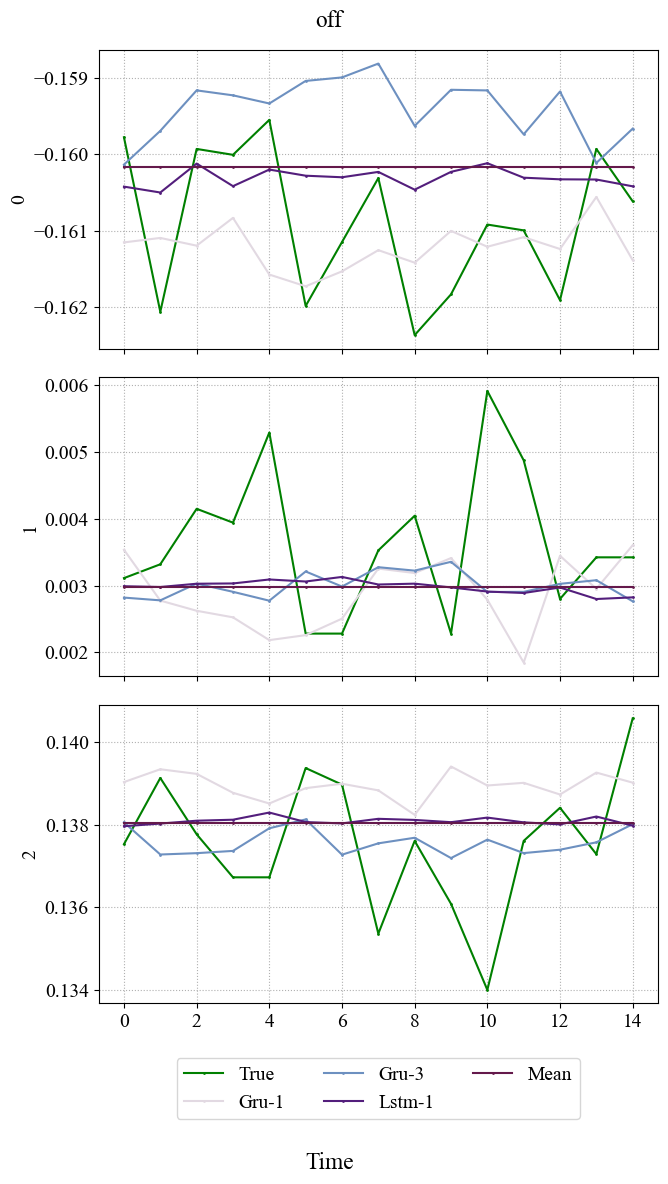

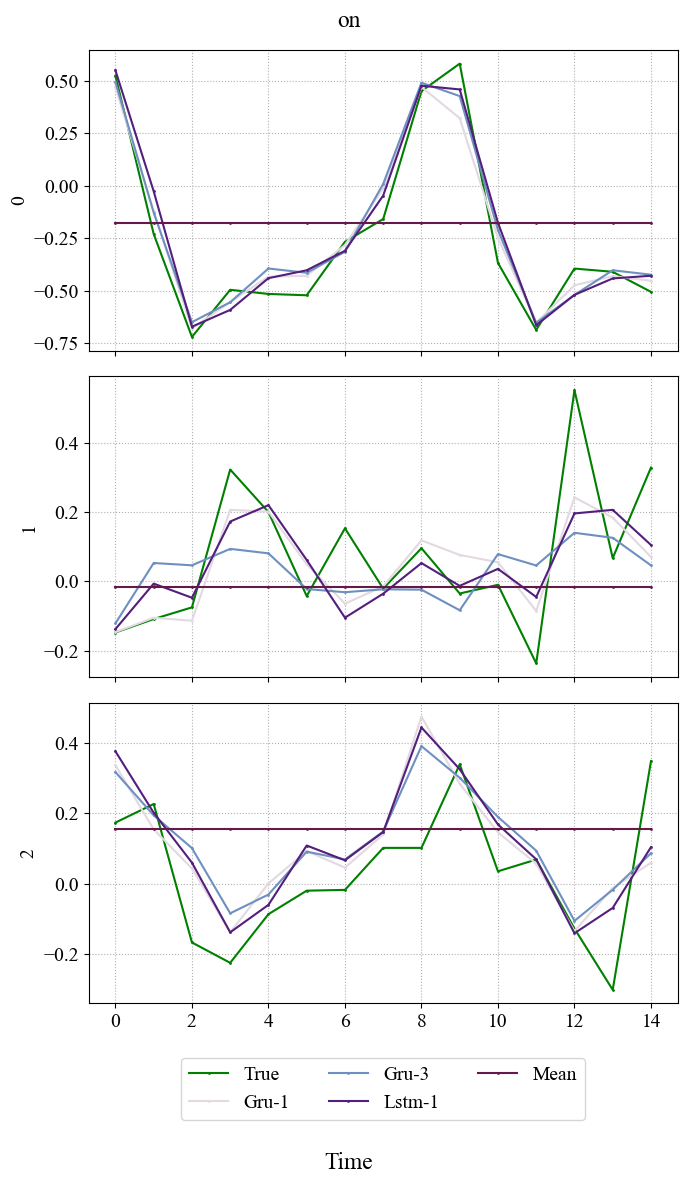

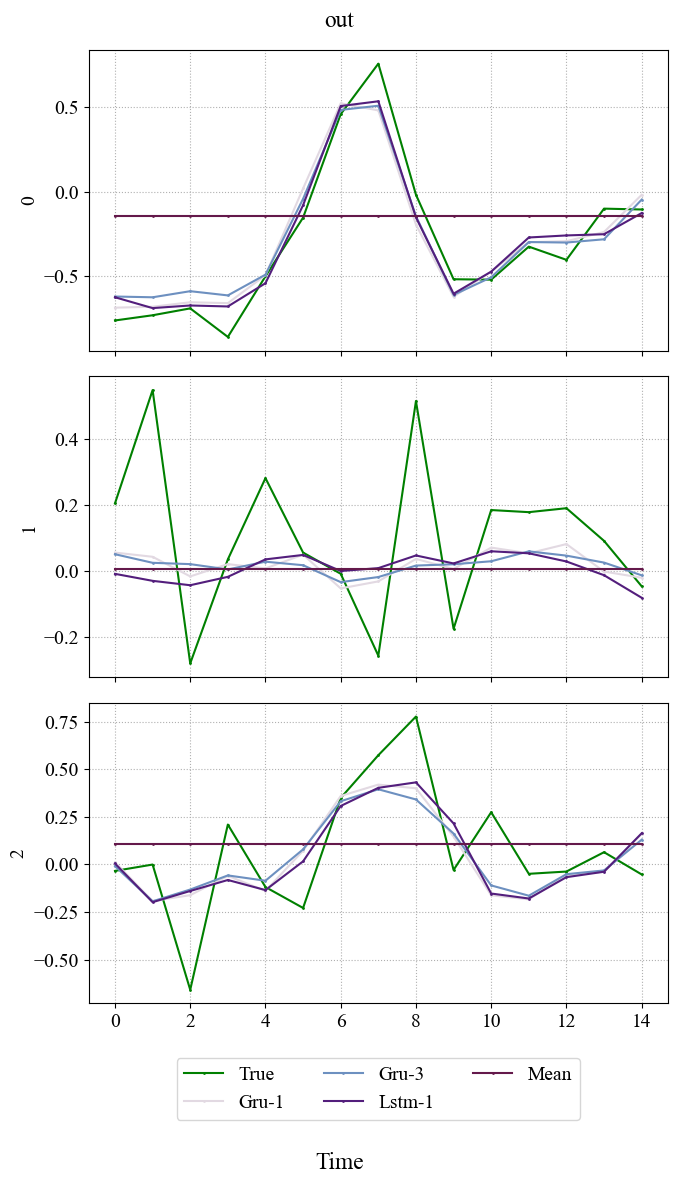

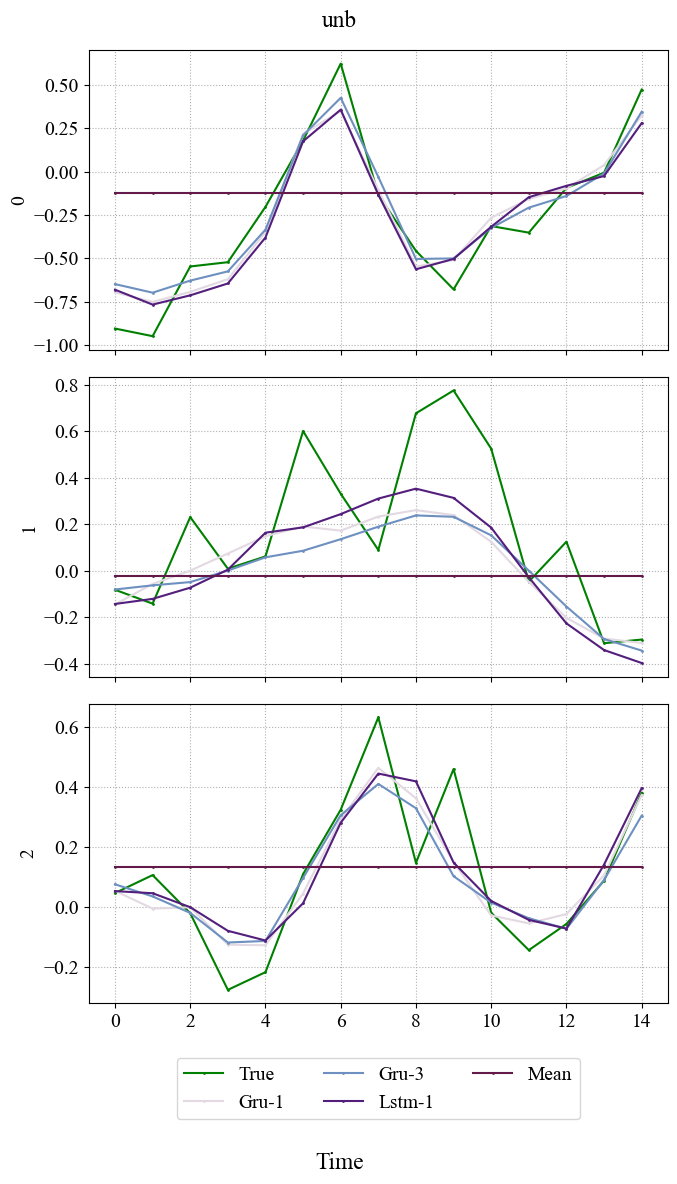

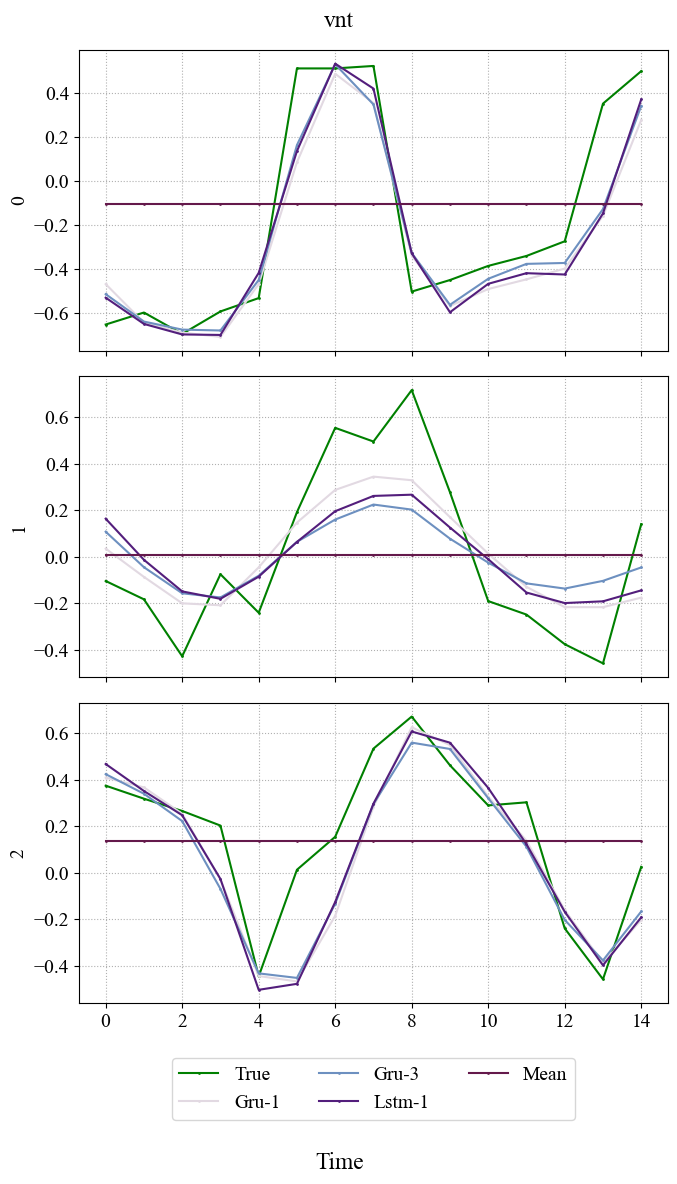

In [33]:
for state, estimator in estimators.items():
    estimator.draw(size=1, draw_horizon=None, title=state)

## This concludes the demonstration for the AI4I-2021 dataset.